# 07 — Presentation: SHAP Feature Importance

## Model & Label Selection

| Choice | Value | Rationale |
|--------|-------|-----------|
| **Detection method** | `gsadf_updown_period` | Highest mean F1 across all four metals in the full 240-experiment benchmark |
| **Prediction model** | LASSO (L1 logistic regression) | Best single model on `gsadf_updown_period` for three out of four metals; interpretable linear structure aligns with SHAP's linear explainer (exact, not approximate) |

### What `gsadf_updown_period` captures
The label combines two complementary GSADF tests: an **upward** explosive episode
(right-tail statistic) *and* a confirmatory **downward** collapse, then applies
morphological closing to remove single-day noise. This two-sided filter sharply
reduces false positives relative to the raw one-sided GSADF.

### How SHAP values are computed
* The LASSO model is fitted on the first **~80 %** of the chronological sample.
* SHAP is evaluated on the remaining **~20 %** (no look-ahead).
* `LinearExplainer` provides exact, closed-form attributions.
* Features whose mean |SHAP| ≤ 10⁻⁶ (i.e. LASSO-zeroed) are hidden.
* Dot colour = normalised feature value (blue = low, red = high); dot position = SHAP contribution to predicted bubble probability.

In [1]:
import pandas as pd
import numpy as np
import warnings
import os
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')

os.makedirs('../outputs', exist_ok=True)

# ── Load data ─────────────────────────────────────────────────────────────
DATA_PATH = '../outputs/all_labels.csv'
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])

METALS   = {'Cobalt': 'CODALY', 'Copper': 'CUDALY', 'Lithium': 'LIDALY', 'Nickel': 'NIDALY'}
VARIANT  = 'gsadf_updown_period'
MODEL    = 'LASSO'

print(f'Data: {len(df)} rows, dates {df.Date.min().date()} – {df.Date.max().date()}')
print(f'Variant : {VARIANT}')
print(f'Model   : {MODEL}')

c:\Users\z001nhrr\Documents\Code\metals\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Data: 2152 rows, dates 2017-05-10 – 2025-10-31
Variant : gsadf_updown_period
Model   : LASSO


In [ ]:
# ── Human-readable label mapping ──────────────────────────────────────────
TICKER_NAMES = {
    'CODALY':    'Cobalt spot price',
    'CUDALY':    'Copper spot price',
    'LIDALY':    'Lithium spot price',
    'NIDALY':    'Nickel spot price',
    'OIL_WTI':   'WTI Crude Oil',
    'GAS_HHUB':  'Natural Gas (Henry Hub)',
    'USD_INDEX': 'US Dollar Index (DXY)',
    'VIX':       'VIX Fear Index',
    'YIELD_10Y': '10-Year Treasury Yield',
    'GOLD_FUT':  'Gold Futures',
    'MSCI_ETF':  'MSCI World Equity ETF',
    'MSCI_EM':   'MSCI Emerging Markets',
    'SP500':     'S&P 500',
    'QCLN':      'Clean Energy ETF (QCLN)',
    'C_CHR':     'China Coal Energy (HK)',
    'C_US':      'US Coal Corp. (BTU)',
}
TRANSFORM_LABELS = {
    '_Ret_L1':   '→ daily return',
    '_Vol10_L1': '→ 10-day volatility',
    '_Level_L1': '→ price level',
}

def make_readable_label(raw: str) -> str:
    """Convert internal feature name to a clean, human-readable label."""
    for sfx, label in TRANSFORM_LABELS.items():
        if raw.endswith(sfx):
            base = raw[: -len(sfx)]
            name = TICKER_NAMES.get(base, base)
            return f'{name}  {label}'
    return raw


def prepare_features(target_metal, label_variant, df_master):
    """Create lagged feature matrix. No look-ahead."""
    target_col = f'{target_metal}_{label_variant}'
    price_cols = ['CODALY', 'CUDALY', 'LIDALY', 'NIDALY']
    macro_cols = [c for c in df_master.columns
                  if c not in ['Date'] + price_cols
                  and not any(c.startswith(m + '_') for m in
                              ['Cobalt', 'Copper', 'Lithium', 'Nickel'])]
    num_cols = price_cols + macro_cols

    out = pd.DataFrame({'Date': df_master['Date']})
    for col in num_cols:
        safe = df_master[col].clip(lower=0.001)
        lr = np.log(safe).diff()
        out[col + '_Ret_L1']   = lr.shift(1)
        out[col + '_Vol10_L1'] = lr.rolling(10).std().shift(1)
    for col in num_cols:
        out[col + '_Level_L1'] = df_master[col].shift(1)

    out['Target'] = df_master[target_col].astype(int)
    return out.dropna().reset_index(drop=True)


def plot_shap_metal(metal, variant, df_master, save=True):
    """Fit LASSO, compute SHAP on last ~20%, plot beeswarm."""
    df_ml = prepare_features(metal, variant, df_master)
    feats = [c for c in df_ml.columns if c not in ['Date', 'Target']]
    X_all = df_ml[feats].values
    y_all = df_ml['Target'].values

    n_test = max(100, len(X_all) // 5)
    X_tr, X_te = X_all[:-n_test], X_all[-n_test:]
    y_tr        = y_all[:-n_test]

    sc   = StandardScaler()
    X_tr = sc.fit_transform(X_tr)
    X_te = sc.transform(X_te)

    model = LogisticRegression(penalty='l1', solver='saga', C=0.1,
                                max_iter=10000, random_state=42)
    model.fit(X_tr, y_tr)

    explainer = shap.LinearExplainer(model, X_tr)
    sv_raw    = explainer(X_te)

    readable_names = [make_readable_label(f) for f in feats]
    sv_plot = shap.Explanation(
        values        = sv_raw.values,
        base_values   = sv_raw.base_values,
        data          = X_te,
        feature_names = readable_names,
    )

    # Drop LASSO-zeroed features
    mean_abs = np.abs(sv_plot.values).mean(axis=0)
    keep = mean_abs > 1e-6
    n_dropped = (~keep).sum()
    sv_plot = shap.Explanation(
        values        = sv_plot.values[:, keep],
        base_values   = sv_plot.base_values,
        data          = sv_plot.data[:, keep],
        feature_names = [n for n, k in zip(sv_plot.feature_names, keep) if k],
    )

    n_active = sv_plot.values.shape[1]
    max_disp = min(15, n_active)

    with plt.rc_context({
        'font.size':       12,
        'axes.labelsize':  12,
        'xtick.labelsize': 11,
        'ytick.labelsize': 12,
    }):
        shap.plots.beeswarm(sv_plot, max_display=max_disp, show=False)
        fig = plt.gcf()
        fig.set_size_inches(14, 9)
        fig.subplots_adjust(top=0.88)
        note = f'({n_dropped} zero-weight features hidden)' if n_dropped > 0 else ''
        fig.suptitle(
            f'{metal}  —  Top drivers of bubble predictions  [LASSO]',
            fontsize=15, fontweight='bold', y=0.97,
        )
        if note:
            fig.text(
                0.5, 0.91,
                note,
                ha='center', va='top', fontsize=10, color='#555555',
                transform=fig.transFigure,
            )
        if save:
            fname = f'../outputs/07_shap_{metal.lower()}_lasso.png'
            plt.savefig(fname, dpi=150, bbox_inches='tight', facecolor='white')
            print(f'Saved → {fname}')
        plt.show()

    top_idx = int(np.argmax(np.abs(sv_plot.values).mean(axis=0)))
    print(f'  {metal}: {n_active} active features  |  '
          f'top: {sv_plot.feature_names[top_idx]}')


print('Helpers ready.')

Helpers ready.


## Cobalt — SHAP Beeswarm

Saved → ../outputs/07_shap_cobalt_lasso.png


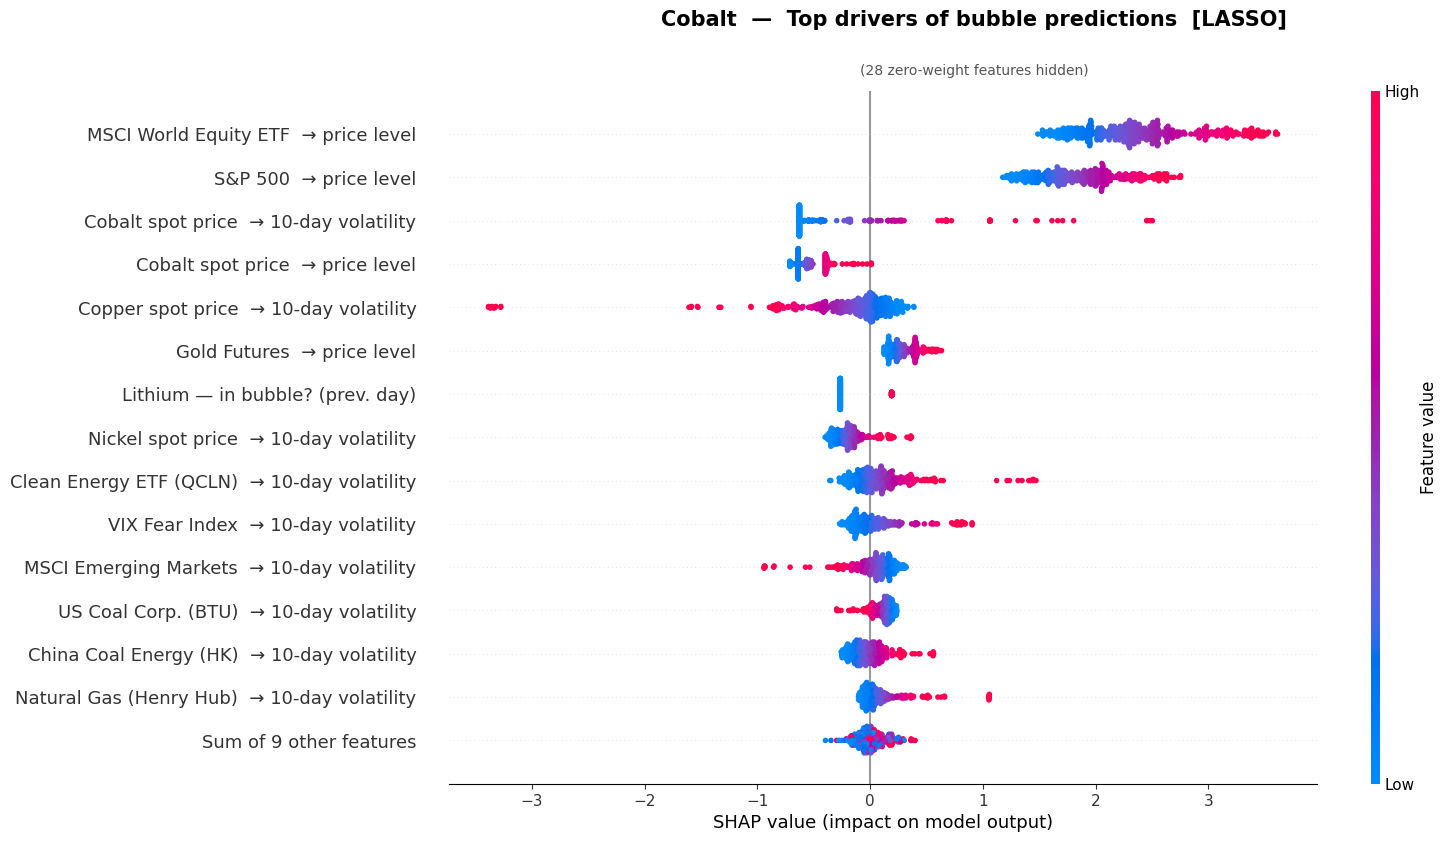

  Cobalt: 23 active features  |  top: MSCI World Equity ETF  → price level


In [8]:
plot_shap_metal('Cobalt', VARIANT, df)

## Copper — SHAP Beeswarm

Saved → ../outputs/07_shap_copper_lasso.png


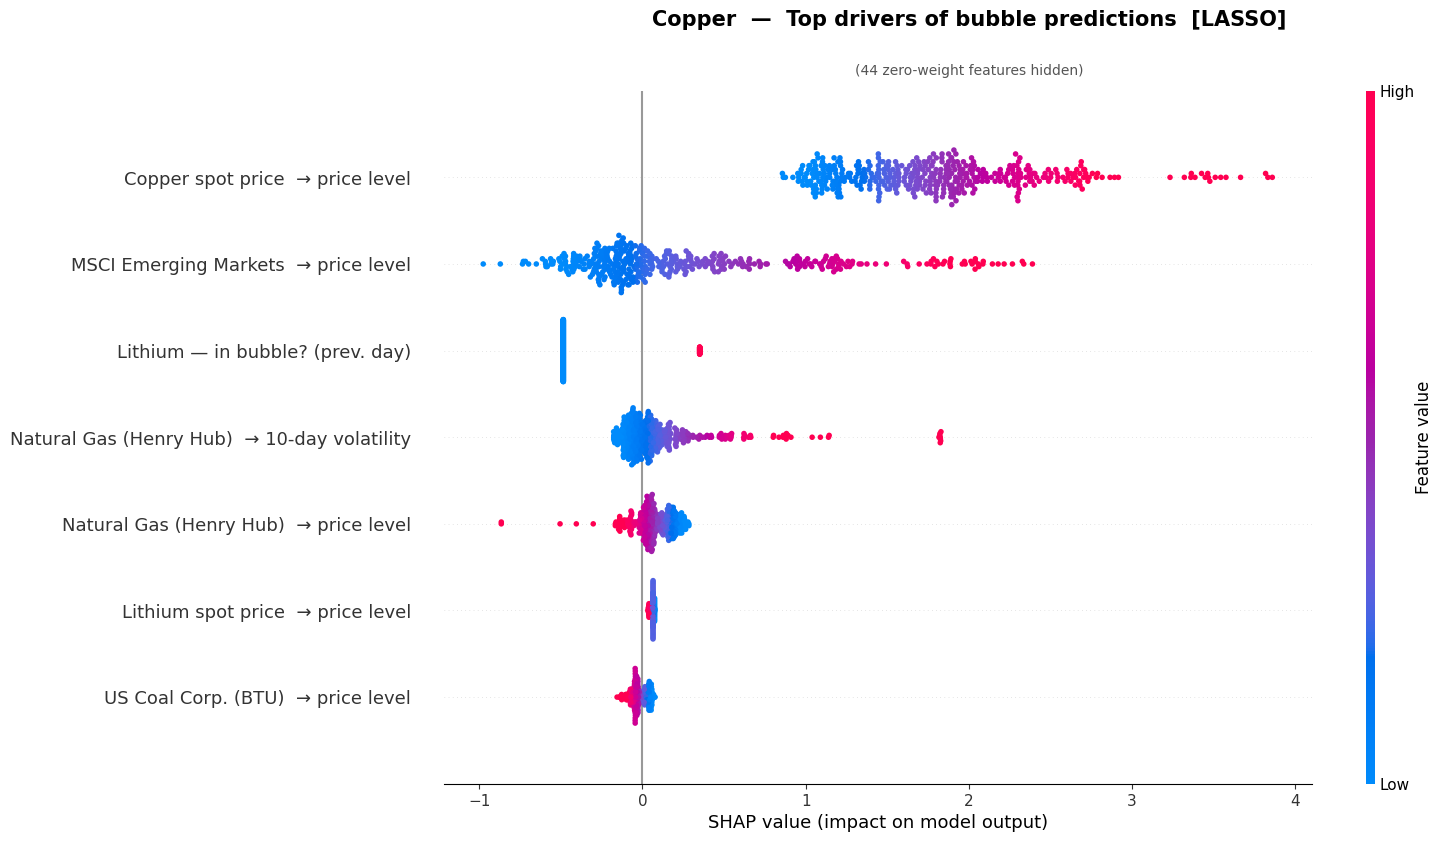

  Copper: 7 active features  |  top: Copper spot price  → price level


In [9]:
plot_shap_metal('Copper', VARIANT, df)

## Lithium — SHAP Beeswarm

Saved → ../outputs/07_shap_lithium_lasso.png


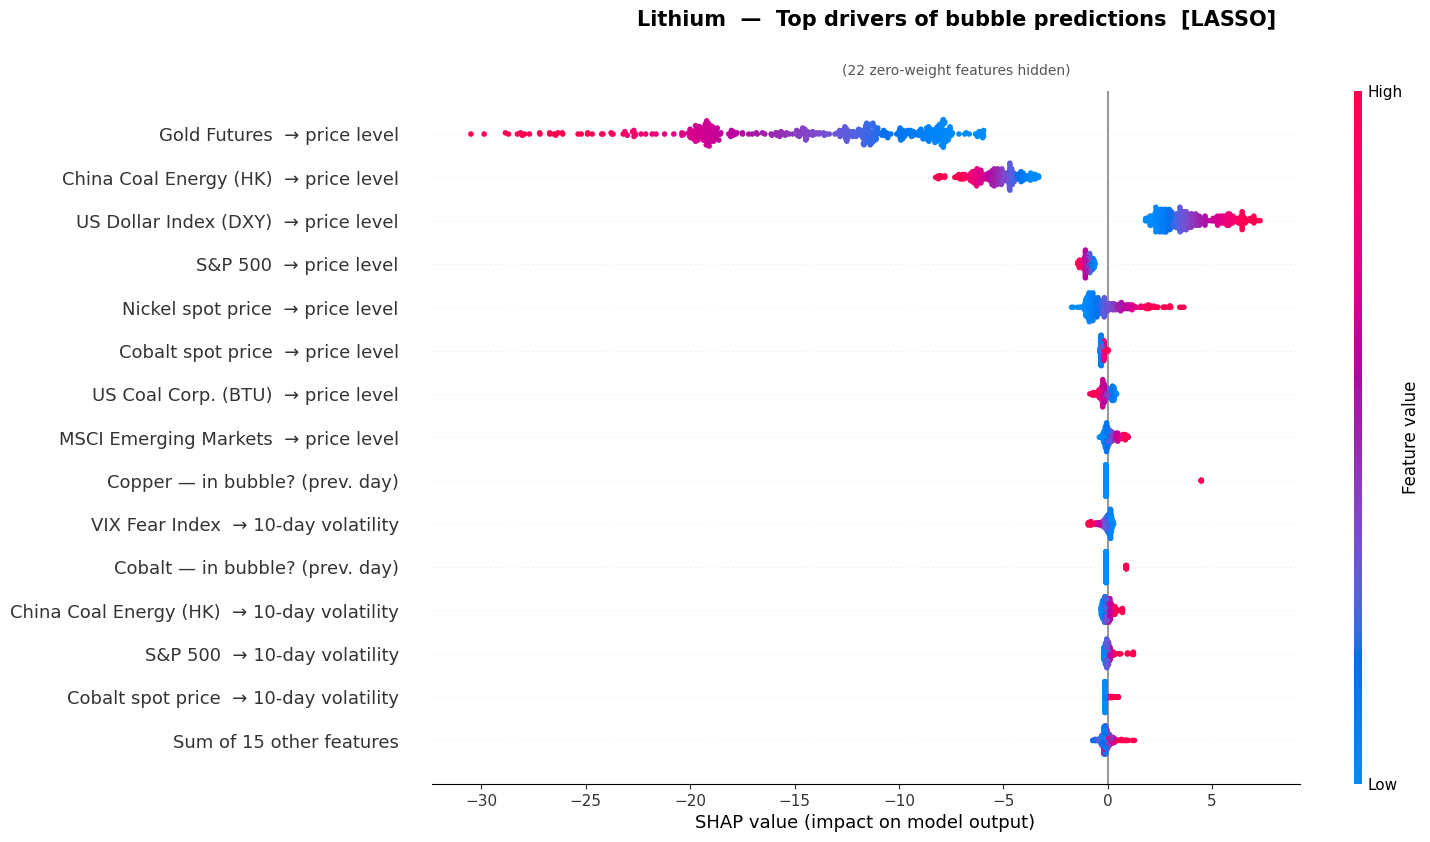

  Lithium: 29 active features  |  top: Gold Futures  → price level


In [10]:
plot_shap_metal('Lithium', VARIANT, df)

## Nickel — SHAP Beeswarm

Saved → ../outputs/07_shap_nickel_lasso.png


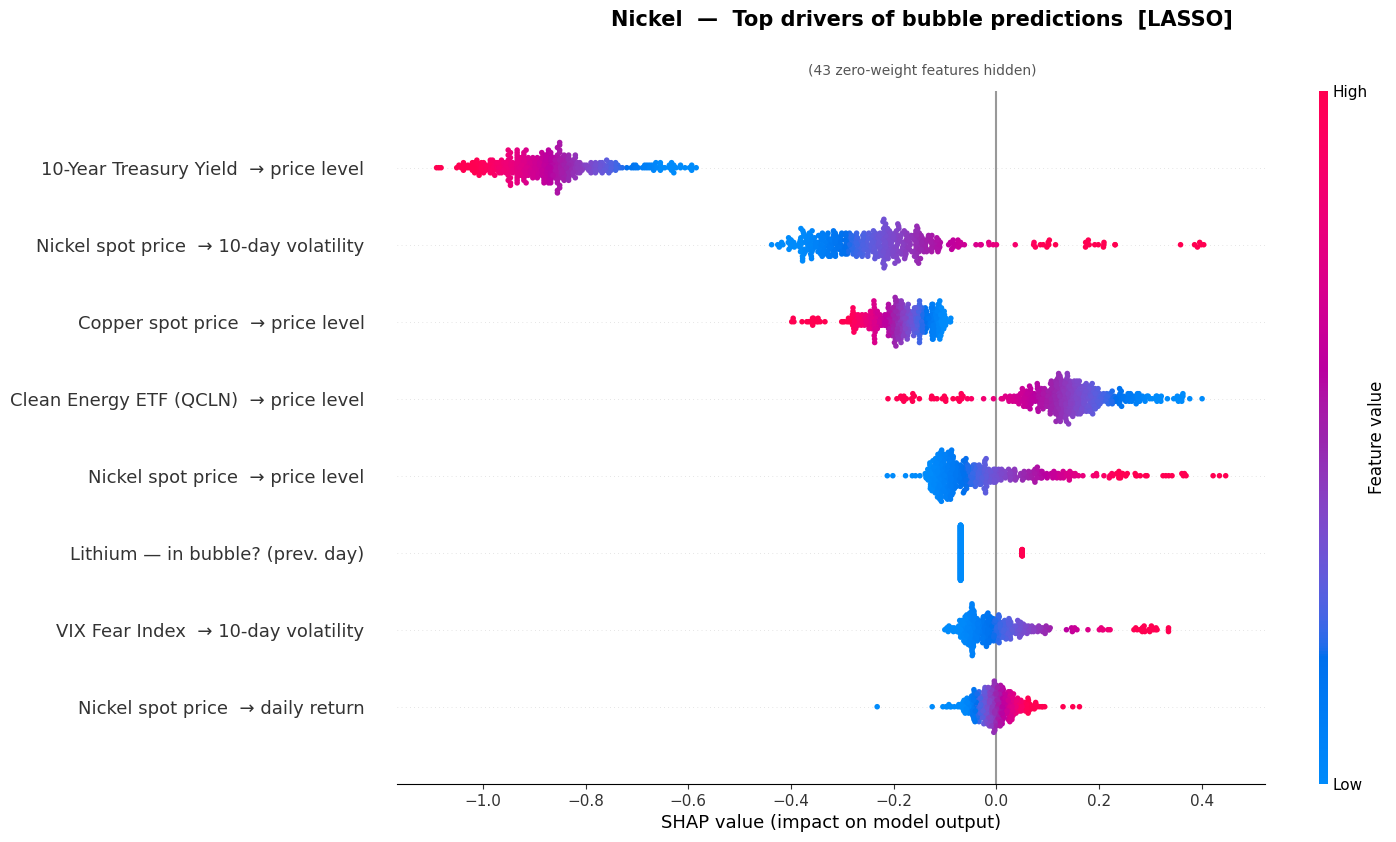

  Nickel: 8 active features  |  top: 10-Year Treasury Yield  → price level


In [11]:
plot_shap_metal('Nickel', VARIANT, df)